# 2. Distribution: nearest source, linear losses

**Distribution poles** are medium poles, small poles, substations and compact substations
(a substation with a medium pole's supply area): everything rated below a big pole. Only they
power machines. An electric network with any distribution pole in it, or with generators, is a
**distribution network**: every pole in it, transmission poles included, is handled here. The
mod does not solve flows in it; it feeds every load from its nearest source:

* **Sources** are the transformer outputs wired into the network, and the poles that pick up
  generators (with their rated output; a solar panel's, what the daylight gives).
* **Loads** are the machine load on each pole and every transformer input wired into the
  network (a transformer drawing from it).
* Distance `d` is resistance-weighted: wire length × mean resistance of its two poles (medium
  2.24, small 5.5, substation 1.55, big 1 per tile).
* Each pole's load goes **whole to its nearest source**: its nearest transformer, or its nearest
  generators while they have output left. A pole is never split. The nearest pairs are served
  first; equally near sources alternate from one pole to the next.
* A transformer input takes from its nearest generators while they have output left, then the
  rest from its nearest transformer.
* How much load a pole carries: by default the network's machine load spread evenly over all
  poles with a supply area; with **machine weighting** (map setting), the machines in each
  pole's supply area (Example 6).
* Power loses `L(d) = 0.025% × d` on the way (capped at 95%), so delivering `w` costs
  `w × L/(1−L)` extra. A transformer pays for the losses on the power it supplies; a
  transformer input reports the loss on what reaches it as its upstream line loss.
* A wire straight from a transmission pole to a distribution pole costs **twice** its
  resistance (map setting): the intended step-down is a transformer.

Machine load: the network's machine load spread evenly over the poles with a supply area (or,
with machine weighting on, by what the machines near each pole draw). Here every pole carries
the same load.

Five examples:
1. One transformer feeding a block: corner or centre
2. One block fed by two transformers
3. A block with a downstream transformer at its far side: medium poles, substations or compact
   substations
4. Mixed poles: a distribution pole in a transmission line, and a big-pole spur into a block
5. Generators: a steam field stepped up by one transformer, and solar inside a block
6. Machine weighting off and on

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import lineloss_model as m

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})


def draw_tree(ax, poles, wires, r, title, colour_by="distance", owners=None):
    """Wires sized by power, poles coloured by distance from their nearest source (or by owner)."""
    m.draw(ax, poles, wires, None, labels=None, colorbar=False, title=title)
    pts = [p for p in r["region"]]
    if colour_by == "distance":
        d = [r["region"][p][1] for p in pts]
        sc = ax.scatter([poles[p][0] for p in pts], [poles[p][1] for p in pts], c=d, cmap="plasma",
                        s=40, zorder=7, edgecolor="k", linewidth=0.4)
        plt.colorbar(sc, ax=ax, label="distance d from the nearest source (tiles, resistance-weighted)", shrink=0.75)
    else:
        palette = {o: c for o, c in zip(sorted(set(owners.values())), ("#3b6fb6", "#d85a30", "#1d9e75"))}
        ax.scatter([poles[p][0] for p in pts], [poles[p][1] for p in pts],
                   c=[palette[r["region"][p][0]] for p in pts], s=40, zorder=7, edgecolor="k", linewidth=0.4)


SOURCE_COLOURS = ("#3b6fb6", "#d85a30", "#1d9e75", "#ba7517")


def draw_sources(ax, poles, wires, r, title, names):
    """Each pole coloured by the source feeding it. names: {source: label}."""
    m.draw(ax, poles, wires, None, labels=None, colorbar=False, title=title)
    colour = {src: SOURCE_COLOURS[i] for i, src in enumerate(names)}
    for p, fed in r["fed_by"].items():
        main = max(fed, key=fed.get)
        split = len([x for x in fed.values() if x > 0.02 * sum(fed.values())]) > 1
        ax.scatter([poles[p][0]], [poles[p][1]], c=[colour.get(main, "grey")], s=40, zorder=7,
                   edgecolor="k" if not split else "red", linewidth=0.4 if not split else 1.6)
    for src, label in names.items():
        ax.scatter([], [], c=[colour[src]], s=40, edgecolor="k", label=label)
    ax.legend(fontsize=7, loc="upper right")


def settle(poles, wires, machines, outs, inputs=None, generators=None, split=None, rounds=5):
    """Run the model with each transformer output delivering what it would in game: the loads
    minus what generators supply, divided between the outputs (equal shares unless split gives
    them). Each output's line loss comes on top of what it delivers."""
    inputs, generators = inputs or {}, generators or {}
    split = split or {o: 1 / len(outs) for o in outs}
    need = sum(machines.values()) + sum(inputs.values())
    total = need
    for _ in range(rounds):
        r = m.solve(poles, wires, {o: total * split[o] for o in outs}, inputs, machines, generators=generators)
        gen = sum(v for k, v in r["supplied"].items() if k.startswith("gen:"))
        total = need - gen
    return r

## Example 1: one transformer feeding a block, corner or centre

A 9 × 9 block of medium poles, 7 tiles apart (56 × 56 tiles), 0.5 MW on every pole (40.5 MW).
T1's output is wired either to the corner pole or to the centre pole.

corner: downstream line loss 3.27%, farthest pole d = 255, busiest wire 40.5 MW
centre: downstream line loss 1.86%, farthest pole d = 130, busiest wire 40.5 MW


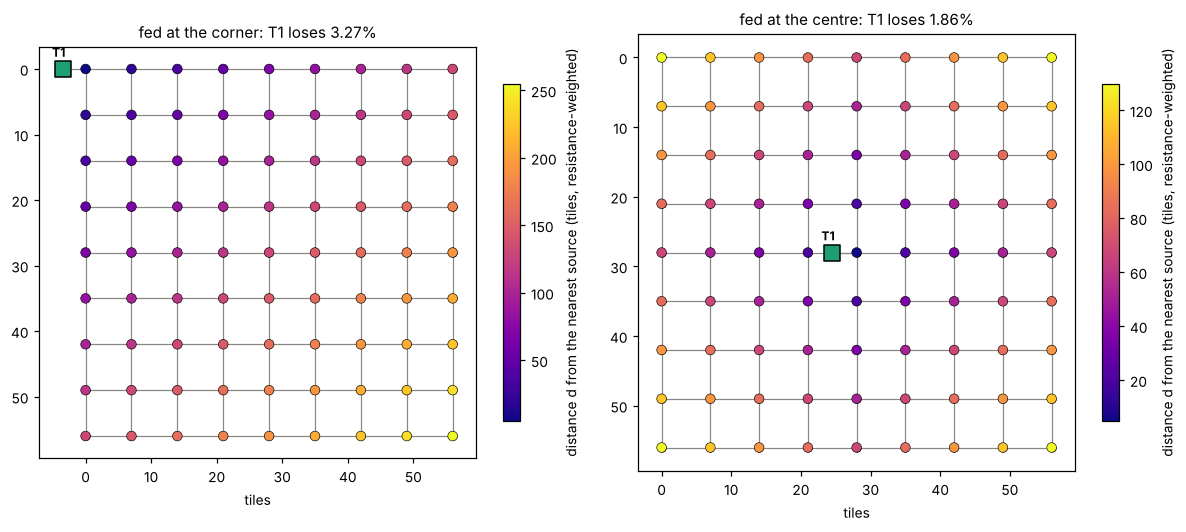

In [2]:
def block_fed(at, per_pole=0.5e6, n=9, kind="medium", spacing=7):
    poles, wires = {}, []
    g = m.grid(poles, wires, "g", 0, 0, n, n, spacing, kind)
    i, j = at
    x, y = poles[g[i, j]][0], poles[g[i, j]][1]
    t1i, t1o = m.transformer(poles, "T1", x - 3.5, y)
    wires.append((t1o, g[i, j]))
    machines = {p: per_pole for p in g.values()}
    total = per_pole * len(g)
    r = m.solve(poles, wires, {t1o: total}, {}, machines)
    return poles, wires, r, t1o, g


fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (name, at) in zip(axes, (("corner", (0, 0)), ("centre", (4, 4)))):
    poles, wires, r, t1o, g = block_fed(at)
    draw_tree(ax, poles, wires, r, f"fed at the {name}: T1 loses {r['down'][t1o]:.2%}")
    far = max(r["region"].values(), key=lambda v: v[1])[1]
    print(f"{name:6s}: downstream line loss {r['down'][t1o]:.2%}, farthest pole d = {far:.0f}, "
          f"busiest wire {max(r['flow'].values()) / 1e6:.1f} MW")
plt.tight_layout()
plt.show()

Colour is each pole's distance from the transformer. From the corner the farthest pole is twice
as far as from the centre (d 255 against 130), and feeding at the centre cuts the loss by about
40% (3.3% to 1.9%). All the power enters at one pole, so the wires next to the transformer
carry the most: in game those are the ones that overload first.

## Example 2: one block, two transformers

The same block fed from two opposite corners by T1 and T2. Every pole goes whole to its nearest
transformer.

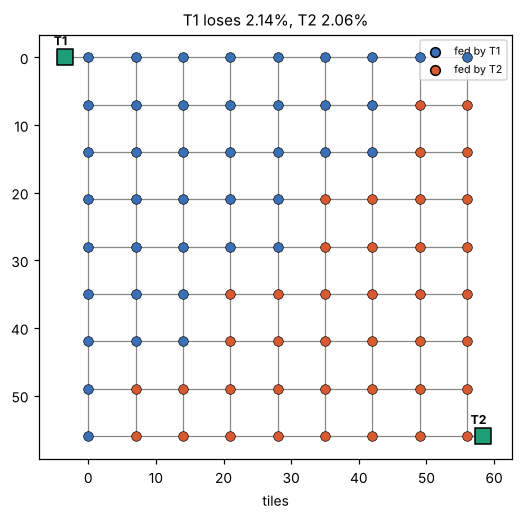

T1 feeds 20.50 MW of machines, T2 20.00 MW


In [3]:
poles, wires = {}, []
g = m.grid(poles, wires, "g", 0, 0, 9, 9, 7, "medium")
t1i, t1o = m.transformer(poles, "T1", -3.5, 0)
t2i, t2o = m.transformer(poles, "T2", 58.3, 56)
wires += [(t1o, g[0, 0]), (t2o, g[8, 8])]
machines = {p: 0.5e6 for p in g.values()}
r = settle(poles, wires, machines, [t1o, t2o])
fig, ax = plt.subplots(figsize=(5.8, 4.8))
draw_sources(ax, poles, wires, r, f"T1 loses {r['down'][t1o]:.2%}, T2 {r['down'][t2o]:.2%}",
             {t1o: "fed by T1", t2o: "fed by T2"})
plt.tight_layout()
plt.show()
print(f"T1 feeds {r['supplied'][t1o] / 1e6:.2f} MW of machines, T2 {r['supplied'][t2o] / 1e6:.2f} MW")

The block splits along the diagonal: each transformer feeds its own half, and both lose about
2.1%, against 3.3% for one corner feed. The poles on the diagonal are equally near both and
alternate between them. Which poles a transformer feeds depends only on distance, not on how
much it delivers in game: its loss is the losses on its poles, as a share of what it delivers.

## Example 3: a block with a downstream transformer at its far side

T1 feeds a factory block (0.5 MW per pole); at the far corner, T2 takes 20 MW for another
block. T2's input is a load at the far corner, so its power pays the loss of the longest route, and T2 shows it as its upstream line loss.

Three ways to wire the same 56 × 56 area: 9 × 9 medium poles 7 apart, 4 × 4 substations 18
apart, or 4 × 4 compact substations (substation wires, medium supply area: a trunk inside the
block, with medium poles or more compact substations to cover the area in game).

medium    : T1 downstream 4.38% (2.78 MW), T2 upstream 6.52%, farthest distance 255


substation: T1 downstream 3.04% (1.91 MW), T2 upstream 4.54%, farthest distance 177
compact   : T1 downstream 3.04% (1.91 MW), T2 upstream 4.54%, farthest distance 177


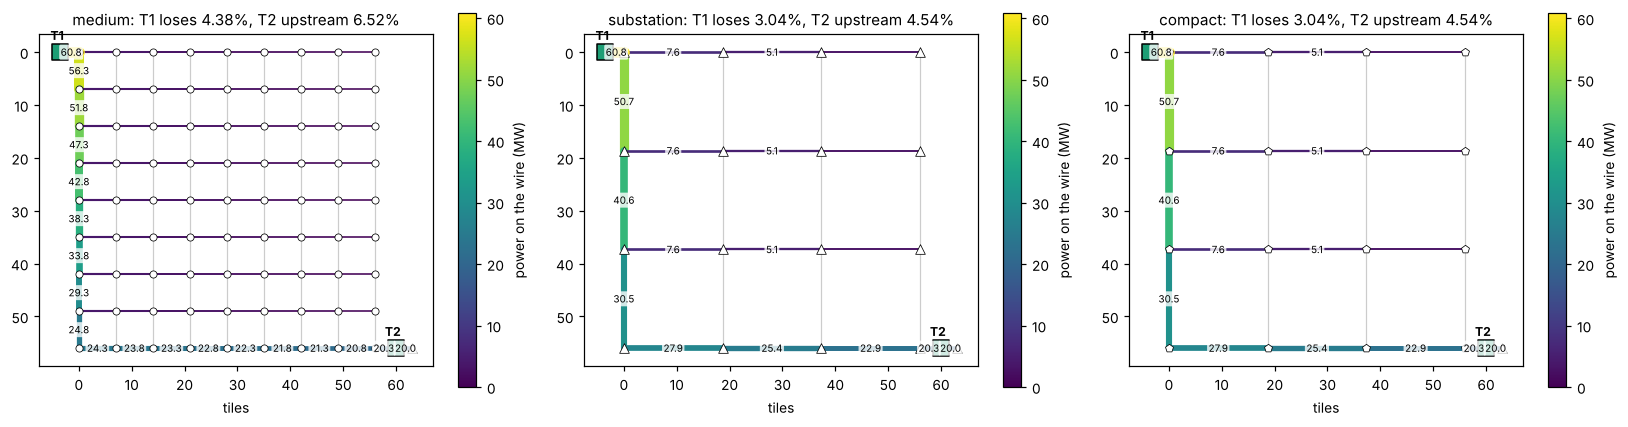

In [4]:
def factory(kind):
    poles, wires = {}, []
    if kind == "medium":
        g = m.grid(poles, wires, "g", 0, 0, 9, 9, 7, "medium")
        far = g[8, 8]
    else:
        g = m.grid(poles, wires, "g", 0, 0, 4, 4, 18.67, kind)
        far = g[3, 3]
    t1i, t1o = m.transformer(poles, "T1", -3.5, 0)
    wires.append((t1o, g[0, 0]))
    fx, fy = poles[far][0], poles[far][1]
    t2i, t2o = m.transformer(poles, "T2", fx + 4, fy)
    wires.append((far, t2i))
    poles["L"] = (fx + 7, fy, "substation")
    wires.append((t2o, "L"))
    total = 40.5e6
    machines = {p: total / len(g) for p in g.values()}
    machines["L"] = 20e6
    extra = {}
    for _ in range(5):
        d2 = (20e6 + extra.get(t2o, 0)) / m.EFFICIENCY + m.CORE_LOSS * m.RATINGS[kind]
        r = m.solve(poles, wires, {t1o: total + d2, t2o: 20e6}, {t2i: d2}, machines)
        extra = r["burn"]
    return poles, wires, r, t1o, t2i


fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, kind in zip(axes, ("medium", "substation", "compact")):
    poles, wires, r, t1o, t2i = factory(kind)
    m.draw(ax, poles, wires, r, labels="flow", min_label=5e6, cmap="viridis",
           title=f"{kind}: T1 loses {r['down'][t1o]:.2%}, T2 upstream {r['up'][t2i]:.2%}")
    print(f"{kind:10s}: T1 downstream {r['down'][t1o]:.2%} ({r['burn'][t1o] / 1e6:.2f} MW), "
          f"T2 upstream {r['up'][t2i]:.2%}, farthest distance "
          f"{max(v[1] for v in r['region'].values()):.0f}")
plt.tight_layout()
plt.show()

With medium poles, T2's 20 MW crosses the whole block on the most resistive wiring: its
upstream loss (6.5%) is the loss of the route to the far corner, and it makes up over half of T1's bill.
Substations cover the same area with fewer, lower-resistance wires: routes are shorter in
resistance-weighted terms, and both losses drop. The compact substation has the substation's
wires, so the same losses; it only powers a smaller area around each pole.

In game: bring big power to the block on transmission (notebook 1), and step down at the
block's edge or centre rather than routing a downstream transformer's power through the factory
wiring.

## Example 4: mixed poles

An electric network is transmission only if all its poles are transmission poles. One
distribution pole wired into it makes the whole network distribution: its big poles become
distribution poles like any other, with linear loss and no Kirchhoff flows. The pole window
shows which kind a network is. A wire straight from a transmission pole to a distribution pole
costs twice its resistance, and so does every wire between transmission poles inside a
distribution network. Four cases, all fed by T1:

* **a. A big line.** T1 to T2 over 124 tiles, 50 MW: transmission, I²R.
* **b. The same line with a medium spur** wired straight to it (5 poles, 2 MW each): the whole
  line is now distribution, its wires cost double, and T2's power pays linear loss.
* **c. The spur behind its own transformer** (T3): the line stays transmission.
* **d. A big-pole spur into a medium block.** A distribution network: the spur's wires cost
  double.

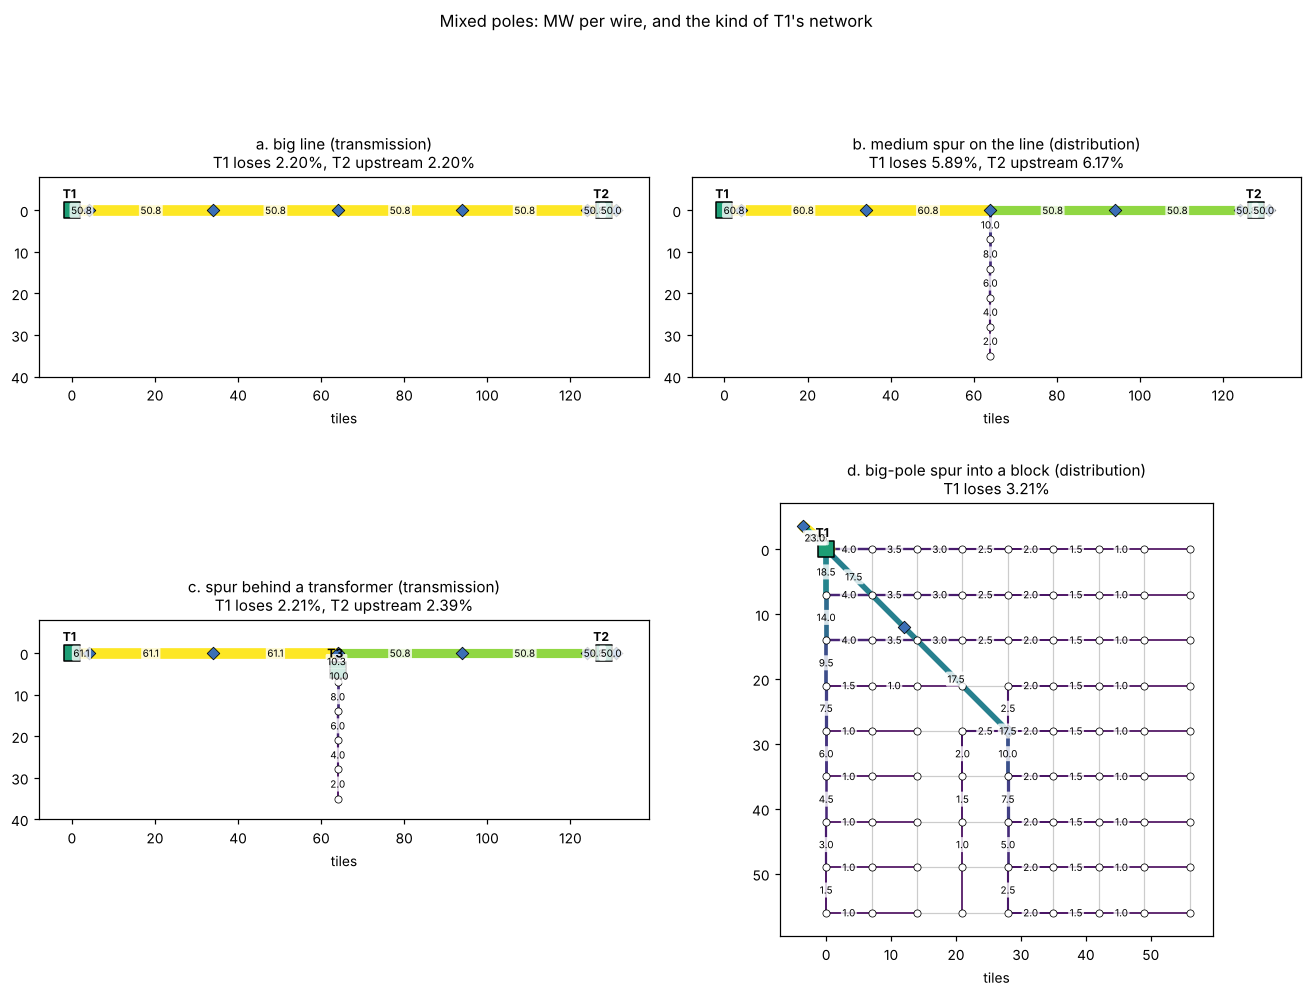

In [5]:
def mixed(case):
    poles, wires, machines, outputs, inputs = {}, [], {}, {}, {}
    t1i, t1o = m.transformer(poles, "T1", 0, 0)
    loads = {}                         # input pole: (output pole, power behind it, core rating)
    if case in "abc":
        a = m.line(poles, wires, "A", (4, 0), (124, 0), 5, "big", first=t1o)
        t2i, t2o = m.transformer(poles, "T2", 128, 0)
        wires.append((a[-1], t2i))
        poles["L2"] = (131, 0, "big"); wires.append((t2o, "L2"))
        machines["L2"] = 50e6
        loads[t2i] = (t2o, 50e6, 300e6)
    if case == "b":
        spur = m.line(poles, wires, "s", (64, 7), (64, 35), 5, "medium", first=a[2])
        machines.update({p: 2e6 for p in spur})
    elif case == "c":
        t3i, t3o = m.transformer(poles, "T3", 64, 4)
        wires.append((a[2], t3i))
        spur = m.line(poles, wires, "s", (64, 7), (64, 35), 5, "medium", first=t3o)
        machines.update({p: 2e6 for p in spur})
        loads[t3i] = (t3o, 10e6, 60e6)
    elif case == "d":
        g = m.grid(poles, wires, "g", 0, 0, 9, 9, 7, "medium")
        poles["P0"] = (-3.5, -3.5, "big"); poles["P1"] = (12, 12, "big"); poles["P2"] = (28, 28, "big")
        wires += [(t1o, "P0"), ("P0", "P1"), ("P1", "P2"), ("P0", g[0, 0]), ("P2", g[4, 4])]
        machines.update({p: 0.5e6 for p in g.values()})
    direct = sum(w for p, w in machines.items() if p != "L2" and not (case == "c" and p.startswith("s")))
    extra = {}
    for _ in range(6):
        ins_ = {i: (w + extra.get(o, 0)) / m.EFFICIENCY + m.CORE_LOSS * rt for i, (o, w, rt) in loads.items()}
        outs = {t1o: direct + sum(ins_.values())}
        outs.update({o: w for o, w, _ in loads.values()})
        r = m.solve(poles, wires, outs, ins_, machines)
        extra = r["burn"]
    return poles, wires, r, t1o


titles = {"a": "a. big line", "b": "b. medium spur on the line", "c": "c. spur behind a transformer",
          "d": "d. big-pole spur into a block"}
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, case in zip(axes.flat, "abcd"):
    poles, wires, r, t1o = mixed(case)
    kind = r["network"]["A0" if case != "d" else "P1"]
    up2 = f", T2 upstream {r['up']['T2.in']:.2%}" if "T2.in" in r["up"] else ""
    m.draw(ax, poles, wires, r, labels="flow", min_label=0.9e6, colorbar=False,
           title=f"{titles[case]} ({kind})\nT1 loses {r['down'][t1o]:.2%}{up2}")
    if case != "d":
        ax.set_ylim(40, -8)
plt.suptitle("Mixed poles: MW per wire, and the kind of T1's network", y=1.0)
plt.tight_layout()
plt.show()

In **a**, 50 MW on a big line is below its reference (75 MW), so I²R loses less than the plain
0.025% per tile. In **b**, the spur's medium poles make the line distribution: T2's 50 MW now
pays the linear rate over the line, at double resistance. In **c**, T3 keeps the spur in its
own network and the line stays transmission.

In [6]:
corner = block_fed((0, 0))
centre = block_fed((4, 4))
spur = mixed("d")
m.MIXED = 1
spur_free = mixed("d")
m.MIXED = 2
print(f"9 x 9 medium block, 40.5 MW: fed at the corner {corner[2]['down'][corner[3]]:.2%}, "
      f"at the centre {centre[2]['down'][centre[3]]:.2%}, "
      f"at the corner with a big-pole spur to the centre {spur[2]['down'][spur[3]]:.2%} "
      f"(without the mixed-wire surcharge: {spur_free[2]['down'][spur_free[3]]:.2%})")

9 x 9 medium block, 40.5 MW: fed at the corner 3.27%, at the centre 1.86%, at the corner with a big-pole spur to the centre 3.21% (without the mixed-wire surcharge: 2.52%)


**The big-pole spur.** Inside the block its wires cost 2 per tile (big pole 1, doubled) against
2.24 for medium poles, so it barely shortens the routes: it saves almost nothing over the corner
feed, while a transformer at the centre cuts the loss by 40%. Without the doubling (setting at
1) the spur would save about a quarter.

## Example 5: generators

Generators have no supply area: distribution poles pick their power up, and a network with
generators is distribution. A pole picking up generators is a source with their rated output.
A transformer stepping their power up is a load like any other: the nearest generators feed it
first, each up to its rating, then the next nearest.

In game, Factorio runs all generators on a network at the same share of their rating. The
order above only decides which routes the power is charged for, the way the nearest cables would
carry it.

A steam field: 12 medium poles 7 tiles apart, each picking up two 0.9 MW engines (21.6 MW
rated). The transformer draws 14 MW. **a**: transformer at one end. **b**: in the middle.

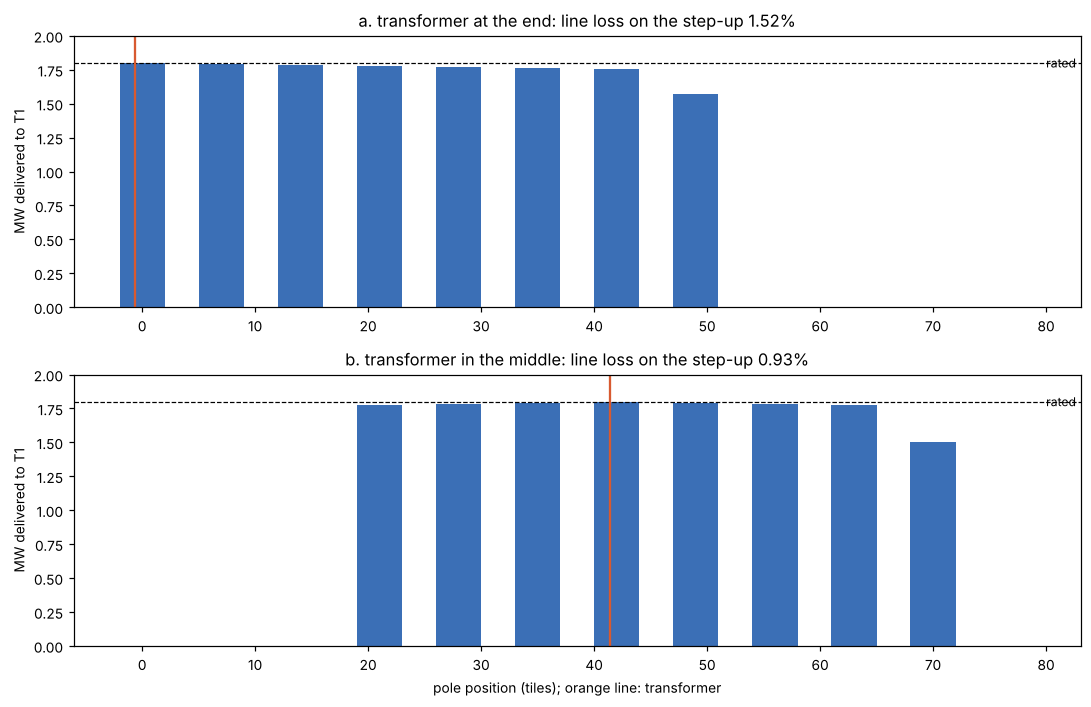

In [7]:
def steam(at):
    poles, wires = {}, []
    xs = [7 * i for i in range(12)]
    t1i, t1o = m.transformer(poles, "T1", xs[at], 4)
    prev = None
    for i, x in enumerate(xs):
        poles[f"g{i}"] = (x, 0, "medium")
        if prev:
            wires.append((prev, f"g{i}"))
        prev = f"g{i}"
    wires.append((f"g{at}", t1i))
    poles["L"] = (xs[at] - 3, 8, "big"); wires.append((t1o, "L"))
    gens = {f"g{i}": 1.8e6 for i in range(12)}
    r = m.solve(poles, wires, {t1o: 14e6 * m.EFFICIENCY}, {t1i: 14e6}, {"L": 14e6 * m.EFFICIENCY}, generators=gens)
    return poles, wires, r, t1i


fig, axes = plt.subplots(2, 1, figsize=(10, 6.5))
for ax, (label, at) in zip(axes, (("a. transformer at the end", 0), ("b. transformer in the middle", 6))):
    poles, wires, r, t1i = steam(at)
    sh = r["gen_share"][t1i]
    xs = [poles[f"g{i}"][0] for i in range(12)]
    ax.bar(xs, [sh.get(f"g{i}", 0) / 1e6 for i in range(12)], width=4, color="#3b6fb6")
    ax.axhline(1.8, color="k", lw=0.8, ls="--")
    ax.text(xs[-1] + 3, 1.8, "rated", va="center", fontsize=8)
    ax.axvline(poles[t1i][0], color="#d85a30", lw=1.5)
    ax.set_ylabel("MW delivered to T1")
    ax.set_ylim(0, 2)
    ax.set_title(f"{label}: line loss on the step-up {r['up'][t1i]:.2%}")
axes[-1].set_xlabel("pole position (tiles); orange line: transformer")
plt.tight_layout()
plt.show()

The nearest engines are used up to their rating (each delivers a little under 1.8 MW: the rest
is lost on its route) and the farthest are not needed. In the middle the routes are half as
long and the step-up loses less.

**Solar inside a block.** The two-transformer block of Example 2, with a 3 MW solar field
picked up by one pole: at the centre, or next to T1. The panels feed the poles nearest to
them; the transformers cover the rest, each from its own side, and deliver 3 MW less between
them (half each, as in game for two identical transformers).

First the numbers, without and with the solar. "Feeds" is the machine load on the poles
assigned to a transformer; "loses" its line loss in MW; "share" that loss over what the
transformer delivers.

In [8]:
def solar_block(at):
    poles, wires = {}, []
    g = m.grid(poles, wires, "g", 0, 0, 9, 9, 7, "medium")
    t1i, t1o = m.transformer(poles, "T1", -3.5, 0)
    t2i, t2o = m.transformer(poles, "T2", 58.3, 56)
    wires += [(t1o, g[0, 0]), (t2o, g[8, 8])]
    machines = {p: 0.5e6 for p in g.values()}
    gens = {g[at]: 3e6} if at else {}
    r = settle(poles, wires, machines, [t1o, t2o], generators=gens)
    return poles, wires, r, t1o, t2o, g, gens


print(f"{'':22s} {'T1 feeds':>9s} {'loses':>9s} {'share':>7s} | {'T2 feeds':>9s} {'loses':>9s} {'share':>7s}")
for label, at in (("no solar", None), ("solar at the centre", (4, 4)), ("solar next to T1", (1, 1))):
    poles, wires, r, t1o, t2o, g, gens = solar_block(at)
    row = [f"{r['supplied'][o] / 1e6:6.2f} MW {r['burn'][o] / 1e6:6.3f} MW {r['down'][o]:7.2%}" for o in (t1o, t2o)]
    print(f"{label:22s} {row[0]} | {row[1]}")

                        T1 feeds     loses   share |  T2 feeds     loses   share
no solar                20.50 MW  0.442 MW   2.14% |  20.00 MW  0.425 MW   2.06%
solar at the centre     19.00 MW  0.396 MW   2.07% |  18.50 MW  0.383 MW   2.00%
solar next to T1        17.50 MW  0.415 MW   2.16% |  20.00 MW  0.425 MW   2.22%


At the centre, the panels take poles far from both transformers: each loses fewer MW, and a
smaller share. Next to T1, the panels take T1's six nearest poles, the cheapest it had (the
loss on a pole grows with its distance from the transformer). T1 loses fewer MW, but its
remaining poles are farther on average, so its loss per MW rises slightly.

The transformers still deliver half each, as in game, while the poles assigned to them follow
distance only: next to T1, T1 is assigned 17.5 MW of poles and delivers 18.75 MW, T2 20 MW and
delivers 18.75 MW. A transformer's share is its losses over what it delivers.

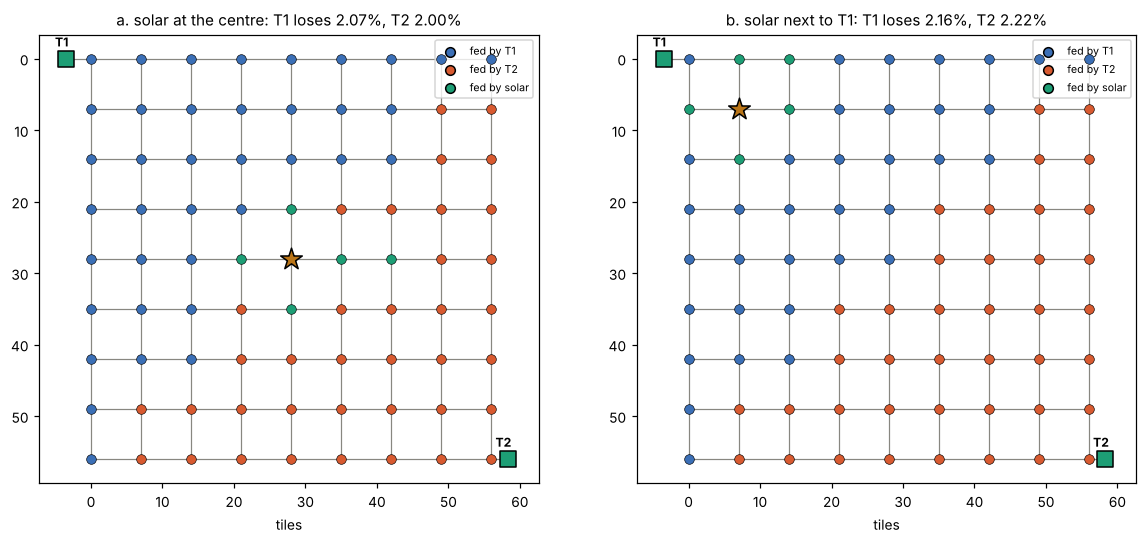

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (label, at) in zip(axes, (("a. solar at the centre", (4, 4)), ("b. solar next to T1", (1, 1)))):
    poles, wires, r, t1o, t2o, g, gens = solar_block(at)
    sun = g[at]
    draw_sources(ax, poles, wires, r, f"{label}: T1 loses {r['down'][t1o]:.2%}, T2 {r['down'][t2o]:.2%}",
                 {t1o: "fed by T1", t2o: "fed by T2", "gen:" + sun: "fed by solar"})
    ax.scatter([poles[sun][0]], [poles[sun][1]], marker="*", s=220, c="#ba7517", edgecolor="k", zorder=8)
plt.tight_layout()
plt.show()

The panels feed the six poles nearest to them (3 MW, 0.5 MW a pole); each transformer feeds
the rest of its own half.

## Example 6: machine weighting off and on

How much load each pole carries:

* **Off** (default): the network's machine load is spread evenly over all poles with a supply
  area, wherever the machines are.
* **On** (map setting "machine weighting"): each pole carries the machines in its supply area. A
  machine covered by two poles counts half on each.

The block of Example 1 fed at the corner, with a light machine (0.2 MW) at every pole and a
cluster of hungry machines (24 MW) at the far corner (**b**) or next to T1 (**c**). Dot size is
the load on each pole; colour, its distance from T1.

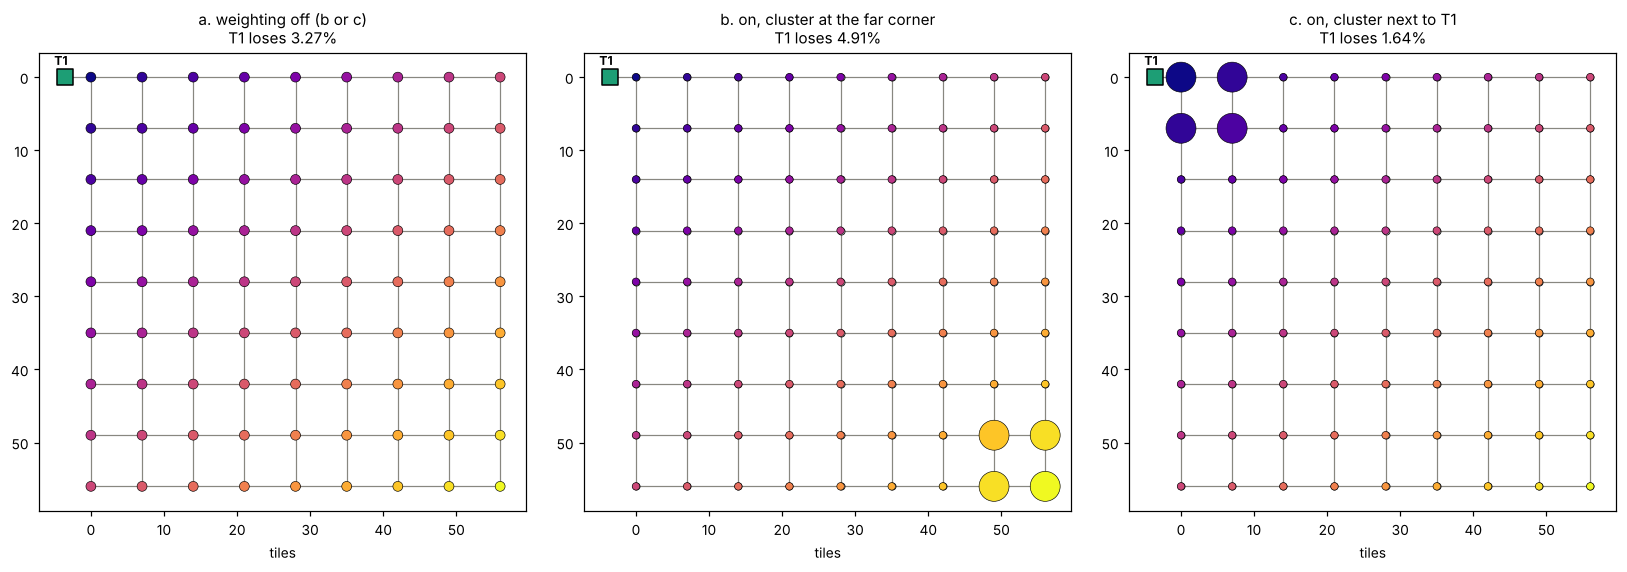

                                    T1 feeds     loses   share
a. weighting off (b or c)           40.20 MW  1.359 MW   3.27%
b. on, cluster at the far corner    40.20 MW  2.076 MW   4.91%
c. on, cluster next to T1           40.20 MW  0.670 MW   1.64%


In [10]:
def weighted_block(cluster_at, weighting):
    poles, wires = {}, []
    g = m.grid(poles, wires, "g", 0, 0, 9, 9, 7, "medium")
    t1i, t1o = m.transformer(poles, "T1", -3.5, 0)
    wires.append((t1o, g[0, 0]))
    machine_list = [(poles[p][0] + 1.5, poles[p][1] + 1.5, 0.2e6) for p in g.values()]
    for i, j in cluster_at:                          # 3 machines of 2 MW next to each of these poles
        x, y, _ = poles[g[i, j]]
        machine_list += [(x - 1.5, y - 1.5, 2e6), (x + 1.5, y - 1.5, 2e6), (x - 1.5, y + 1.5, 2e6)]
    machines = m.machine_loads(poles, machine_list, weighting)
    r = m.solve(poles, wires, {t1o: sum(machines.values())}, {}, machines)
    return poles, wires, r, t1o, machines


far = [(7, 7), (7, 8), (8, 7), (8, 8)]
near = [(0, 0), (0, 1), (1, 0), (1, 1)]
cases = (("a. weighting off (b or c)", far, False), ("b. on, cluster at the far corner", far, True),
         ("c. on, cluster next to T1", near, True))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
rows = []
for ax, (label, at, wgt) in zip(axes, cases):
    poles, wires, r, t1o, machines = weighted_block(at, wgt)
    m.draw(ax, poles, wires, None, labels=None, colorbar=False, title=f"{label}\nT1 loses {r['down'][t1o]:.2%}")
    pts = list(machines)
    sc = ax.scatter([poles[p][0] for p in pts], [poles[p][1] for p in pts],
                    s=[12 + 60 * machines[p] / 1e6 for p in pts], c=[r["region"][p][1] for p in pts],
                    cmap="plasma", zorder=7, edgecolor="k", linewidth=0.4)
    rows.append((label, sum(machines.values()), r["burn"][t1o], r["down"][t1o]))
plt.tight_layout()
plt.show()
print(f"{'':34s} {'T1 feeds':>9s} {'loses':>9s} {'share':>7s}")
for label, w, lost, share in rows:
    print(f"{label:34s} {w / 1e6:6.2f} MW {lost / 1e6:6.3f} MW {share:7.2%}")

Without weighting the cluster's position does not matter: every pole carries the same load,
and the loss is that of an evenly loaded block. With weighting, the same load costs half again
as much when the hungry machines sit at the far corner, and half as much when they sit next
to the transformer. Here T1 feeds the whole block, so feeds and delivers are the same and the
share moves with the MW.

**A machine covered by poles of two transformers.** In the two-transformer block of Example 2
(machines weighted), a 4 MW machine placed between a pole fed by T1 and a neighbouring pole fed
by T2 counts half on each: 2 MW goes to T1, 2 MW to T2.

In [11]:
poles, wires = {}, []
g = m.grid(poles, wires, "g", 0, 0, 9, 9, 7, "medium")
t1i, t1o = m.transformer(poles, "T1", -3.5, 0)
t2i, t2o = m.transformer(poles, "T2", 58.3, 56)
wires += [(t1o, g[0, 0]), (t2o, g[8, 8])]
base = [(poles[p][0] + 1.5, poles[p][1] + 1.5, 0.5e6) for p in g.values()]
r0 = m.solve(poles, wires, {t1o: 20.25e6, t2o: 20.25e6}, {}, m.machine_loads(poles, base, True))
owner = {p: max(f, key=f.get) for p, f in r0["fed_by"].items()}
a_, b_ = next((g[i, j], g[i + 1, j]) for i in range(8) for j in range(9)
              if owner[g[i, j]] == t1o and owner[g[i + 1, j]] == t2o)
mid = ((poles[a_][0] + poles[b_][0]) / 2, poles[a_][1])
loads = m.machine_loads(poles, base + [(mid[0], mid[1], 4e6)], True)
r1 = m.solve(poles, wires, {t1o: 20.25e6, t2o: 20.25e6}, {}, loads)
print(f"machine between {a_} (T1) and {b_} (T2): load on them {loads[a_] / 1e6:.2f} and {loads[b_] / 1e6:.2f} MW; "
      f"T1 feeds {(r1['supplied'][t1o] - r0['supplied'][t1o]) / 1e6:.2f} MW more, "
      f"T2 {(r1['supplied'][t2o] - r0['supplied'][t2o]) / 1e6:.2f} MW more")

machine between g0_7 (T1) and g1_7 (T2): load on them 2.50 and 2.50 MW; T1 feeds 2.00 MW more, T2 2.00 MW more


**A solar field with machine weighting.** The block with the hungry cluster at the far corner,
plus a 12 MW solar field picked up by one pole: at the far corner, by the cluster, or next to
T1. The panels feed the poles nearest to them while they have output left (whole poles, so the
last pole can take them slightly over 12 MW); T1 feeds the rest.

                                            T1 feeds     loses   share     solar
weighting off, no solar                     40.20 MW  1.359 MW   3.27%   0.00 MW
weighting off, solar at the far corner      28.29 MW  0.738 MW   2.54%  11.91 MW
weighting off, solar next to T1             28.29 MW  1.170 MW   3.97%  11.91 MW
weighting on, no solar                      40.20 MW  2.076 MW   4.91%   0.00 MW
weighting on, solar at the far corner       27.80 MW  1.259 MW   4.33%  12.40 MW
weighting on, solar next to T1              28.40 MW  1.762 MW   5.84%  11.80 MW


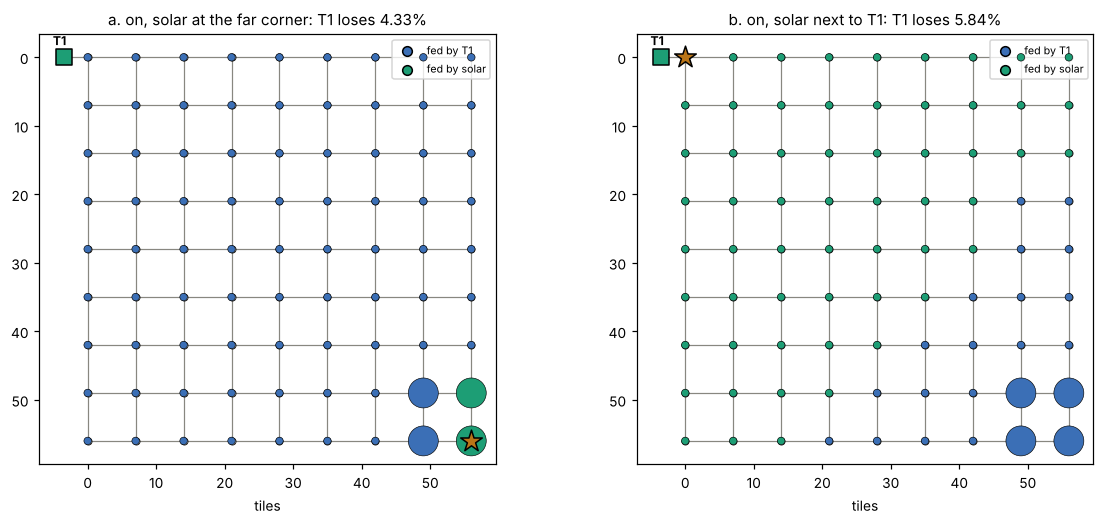

In [12]:
def solar_weighted(solar_at, weighting):
    poles, wires = {}, []
    g = m.grid(poles, wires, "g", 0, 0, 9, 9, 7, "medium")
    t1i, t1o = m.transformer(poles, "T1", -3.5, 0)
    wires.append((t1o, g[0, 0]))
    machine_list = [(poles[p][0] + 1.5, poles[p][1] + 1.5, 0.2e6) for p in g.values()]
    for i, j in far:
        x, y, _ = poles[g[i, j]]
        machine_list += [(x - 1.5, y - 1.5, 2e6), (x + 1.5, y - 1.5, 2e6), (x - 1.5, y + 1.5, 2e6)]
    machines = m.machine_loads(poles, machine_list, weighting)
    gens = {g[solar_at]: 12e6} if solar_at else {}
    need = sum(machines.values())
    for _ in range(3):
        r = m.solve(poles, wires, {t1o: need}, {}, machines, generators=gens)
        need = sum(machines.values()) - sum(v for k, v in r["supplied"].items() if k.startswith("gen:"))
    return poles, wires, r, t1o, machines, g


print(f"{'':42s} {'T1 feeds':>9s} {'loses':>9s} {'share':>7s} {'solar':>9s}")
for wgt in (False, True):
    for label, at in (("no solar", None), ("solar at the far corner", (8, 8)), ("solar next to T1", (0, 0))):
        poles, wires, r, t1o, machines, g = solar_weighted(at, wgt)
        sol = sum(v for k, v in r["supplied"].items() if k.startswith("gen:"))
        print(f"{('weighting on, ' if wgt else 'weighting off, ') + label:42s} {r['supplied'][t1o] / 1e6:6.2f} MW "
              f"{r['burn'][t1o] / 1e6:6.3f} MW {r['down'][t1o]:7.2%} {sol / 1e6:6.2f} MW")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (label, at) in zip(axes, (("a. on, solar at the far corner", (8, 8)), ("b. on, solar next to T1", (0, 0)))):
    poles, wires, r, t1o, machines, g = solar_weighted(at, True)
    m.draw(ax, poles, wires, None, labels=None, colorbar=False, title=f"{label}: T1 loses {r['down'][t1o]:.2%}")
    sun = "gen:" + g[at]
    pts = list(machines)
    ax.scatter([poles[p][0] for p in pts], [poles[p][1] for p in pts], s=[12 + 60 * machines[p] / 1e6 for p in pts],
               c=[SOURCE_COLOURS[2] if sun in r["fed_by"].get(p, {}) else SOURCE_COLOURS[0] for p in pts],
               zorder=7, edgecolor="k", linewidth=0.4)
    ax.scatter([poles[g[at]][0]], [poles[g[at]][1]], marker="*", s=220, c="#ba7517", edgecolor="k", zorder=8)
    ax.scatter([], [], c=SOURCE_COLOURS[0], s=40, edgecolor="k", label="fed by T1")
    ax.scatter([], [], c=SOURCE_COLOURS[2], s=40, edgecolor="k", label="fed by solar")
    ax.legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

Dot size is the load on each pole. Without weighting, every pole carries the same load, so the
panels feed the 24 poles nearest to them wherever the machines are. With weighting, the same
12 MW covers only the two cluster poles beside the panels when they sit at the far corner: the
power is used where it would cost T1 the most to bring, and T1's loss drops by 40%. Next to
T1, the panels take the poles T1 feeds cheaply and T1 still has to reach the cluster: it loses
fewer MW, but its share rises. Local generation pays most next to the hungry machines far from
the transformer.

## What to take away

* Every pole is fed by its nearest source; loss grows with the resistance-weighted distance.
* Feed blocks from the centre or from several sides: routes get shorter.
* With machine weighting, hungry machines far from the transformer cost more than the same
  load near it; without it, only the number and spread of poles count.
* A downstream transformer on a block pays the loss of its route on all the power it takes.
* Substations make shorter routes than medium poles over the same area; small poles longer ones.
* One distribution pole makes its whole network distribution: keep transmission lines clean and
  step down through transformers.
* Generators near a load feed it first: put step-up transformers in the middle of a field, and
  local generation (solar) where the transformers are far.